#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.

In this notebook I have used LLM to help me construct legible plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?
- Each pixel would have at least three values, each corresponding to red, green and blue channel. That way we cannot assume 2D matrix.

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [3]:
img = Image.open("/content/drive/My Drive/DSC_0572.JPG")
imggray = img.convert('L')

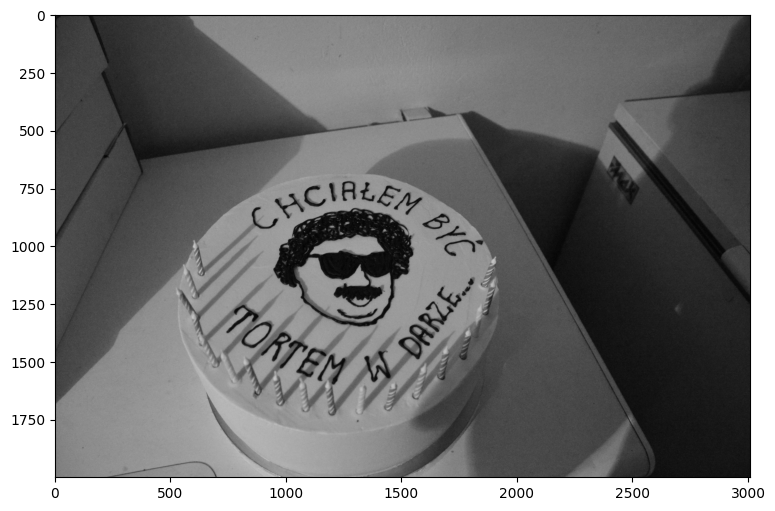

In [4]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

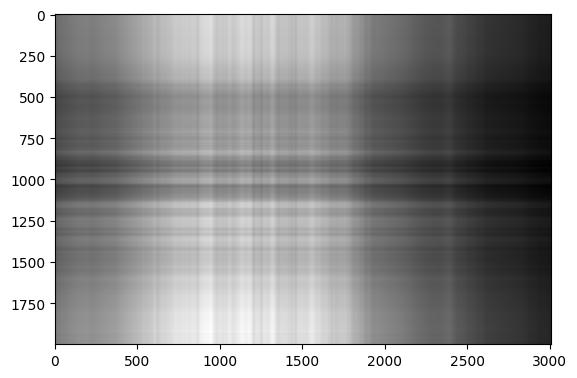

In [5]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

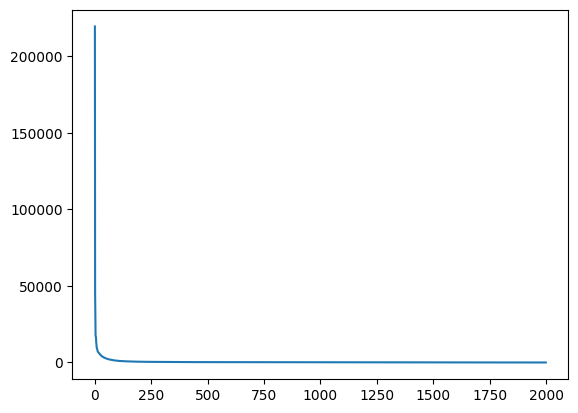

In [6]:
U.shape
sigma.shape
plt.plot(sigma)

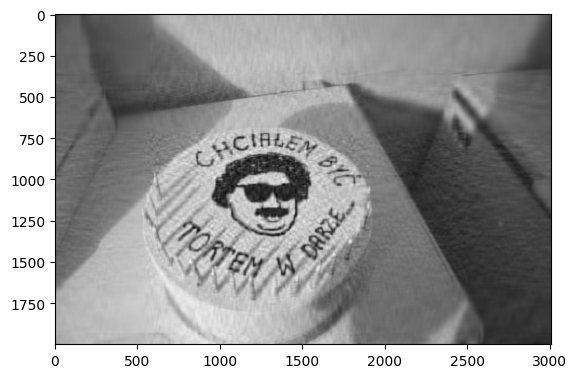

In [7]:
i = 40
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

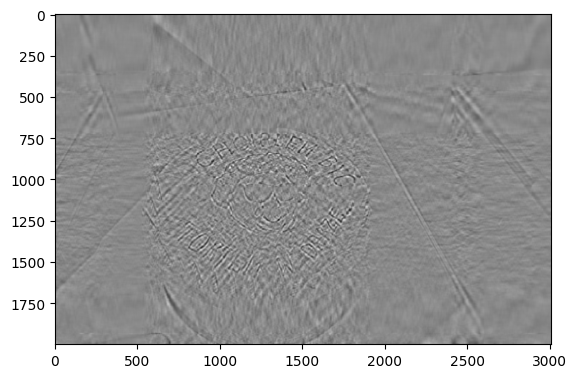

In [8]:
i = 80
j = 40
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

We start to get decent reconstruction around i=40, where we can distinguish easily the objects on the image and read the text. However, when we start to omit first rows (by manipulating the j value) we start to get strange light stripes on our reconstruction. That does not ruin the image, but significantly drops its quality. That shows the importance of the first few vectors, which can also be observed on the sigma plot. Within the very first vectors the sigma value drops drastically towards 0. If we set our i to 80 and j to 40 we still have the reconstruction made of 40 vectors, but the image quality is disastrous. No object can be distinguished, even though the same amount of vectors had been used.

Image size: (1140, 1150)


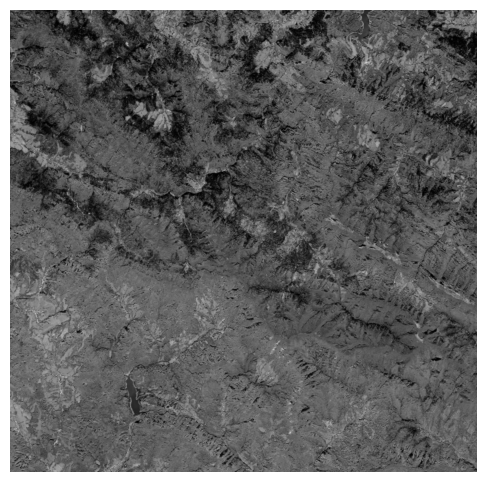

In [9]:
img = Image.open("/content/drive/My Drive/forest.png")
forest = np.array(img.convert('L'), dtype=float)

print("Image size:", forest.shape)
plt.figure(figsize=(8, 6))
plt.imshow(forest, cmap='gray')
plt.axis('off')
plt.show()

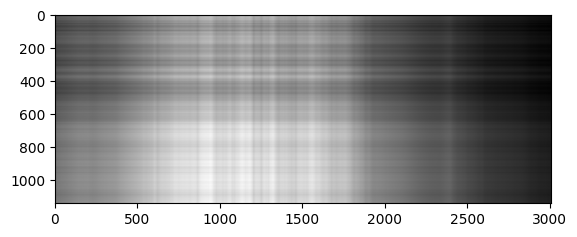

In [10]:
U, sigma, Vt = np.linalg.svd(forest, full_matrices=False)
def reconstruct(U, sigma, Vt, start, stop):
    return U[:, start:stop] @ np.diag(sigma[start:stop]) @ Vt[start:stop, :]
reconstforest = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstforest, cmap='gray');

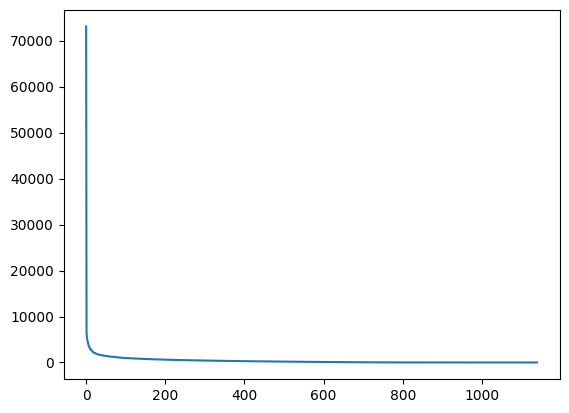

In [11]:
U.shape
sigma.shape
plt.plot(sigma)

As seen previously, the sigma value drops rapidly as the number of layers rise. To answer how many singular values are "good enough" with a number rather than only by eye, we can use the energy of the image. It is the sum of the squares of all its pixel values.
The layers produced by SVD are orthogonal to each other, so their contributions add up like in Pythagoras' theorem.

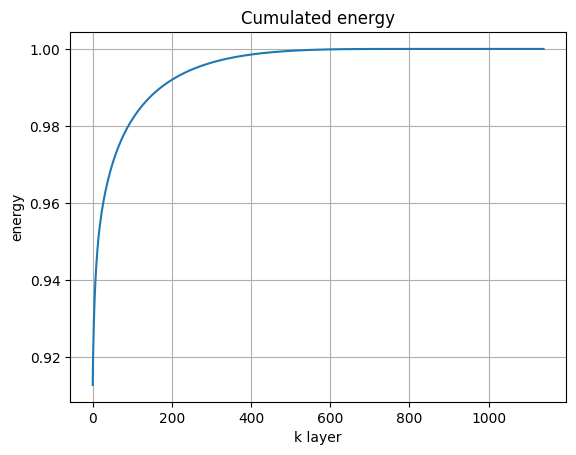

In [12]:
energy = np.cumsum(sigma**2) / np.sum(sigma**2)

for p in [0.90, 0.95, 0.99]:
    k = np.argmax(energy >= p) + 1

plt.plot(energy)
plt.xlabel("k layer")
plt.ylabel("energy")
plt.title("Cumulated energy")
plt.grid(True)
plt.show()

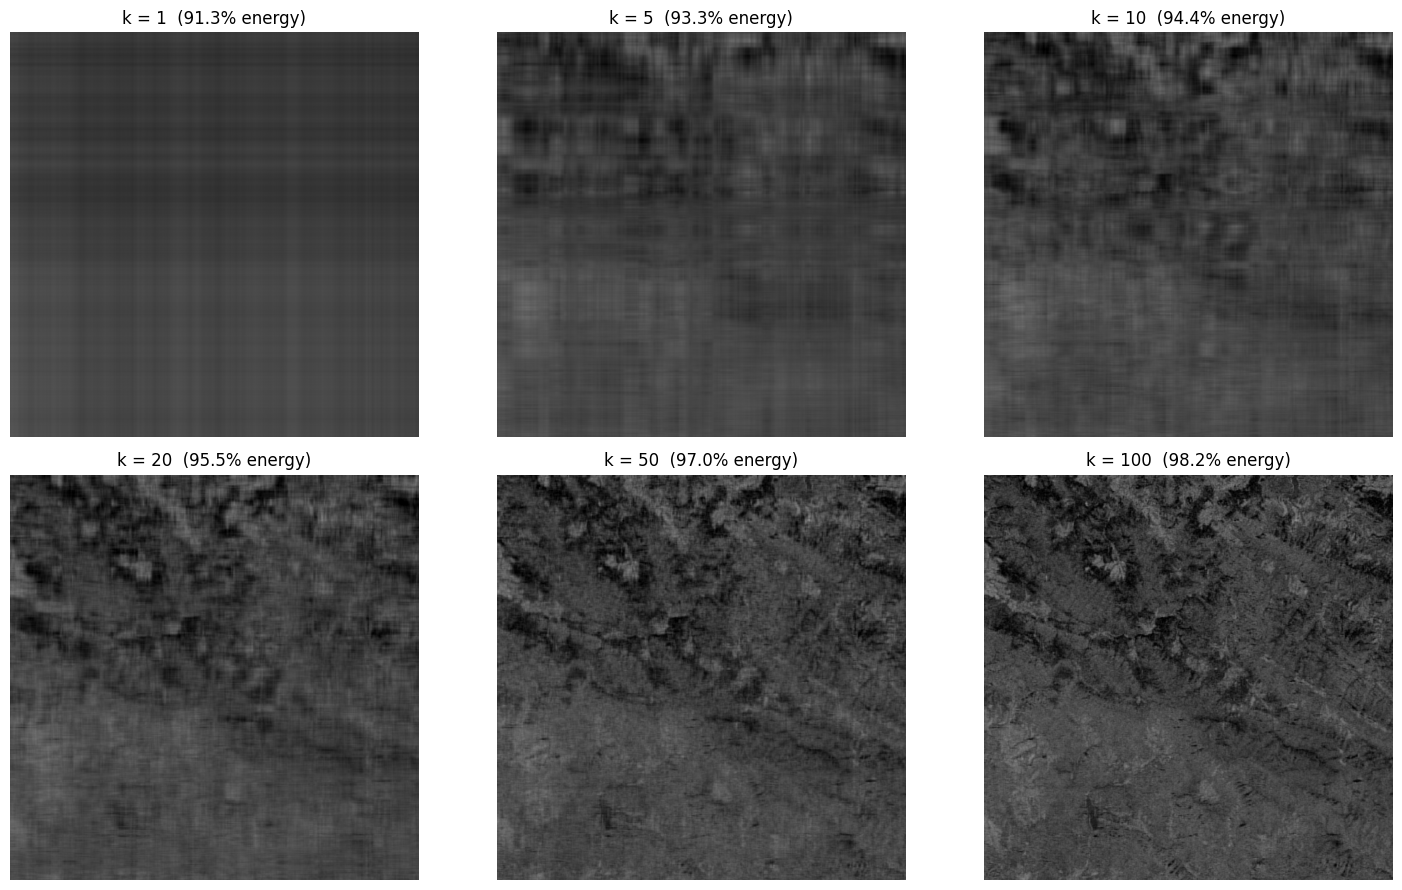

In [13]:
ks = [1, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, k in zip(axes.flat, ks):
    ax.imshow(reconstruct(U, sigma, Vt, 0, k), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"k = {k}  ({energy[k-1]*100:.1f}% energy)")
    ax.axis('off')

plt.tight_layout()
plt.show()

As we can see, the k=50 gives us pretty satisfying result. We can easily tell what is and isn't a forest. It is worth observing, that the 1st layer only have the vast majority of the energy of all layers. This only highlights, how important first layers are.

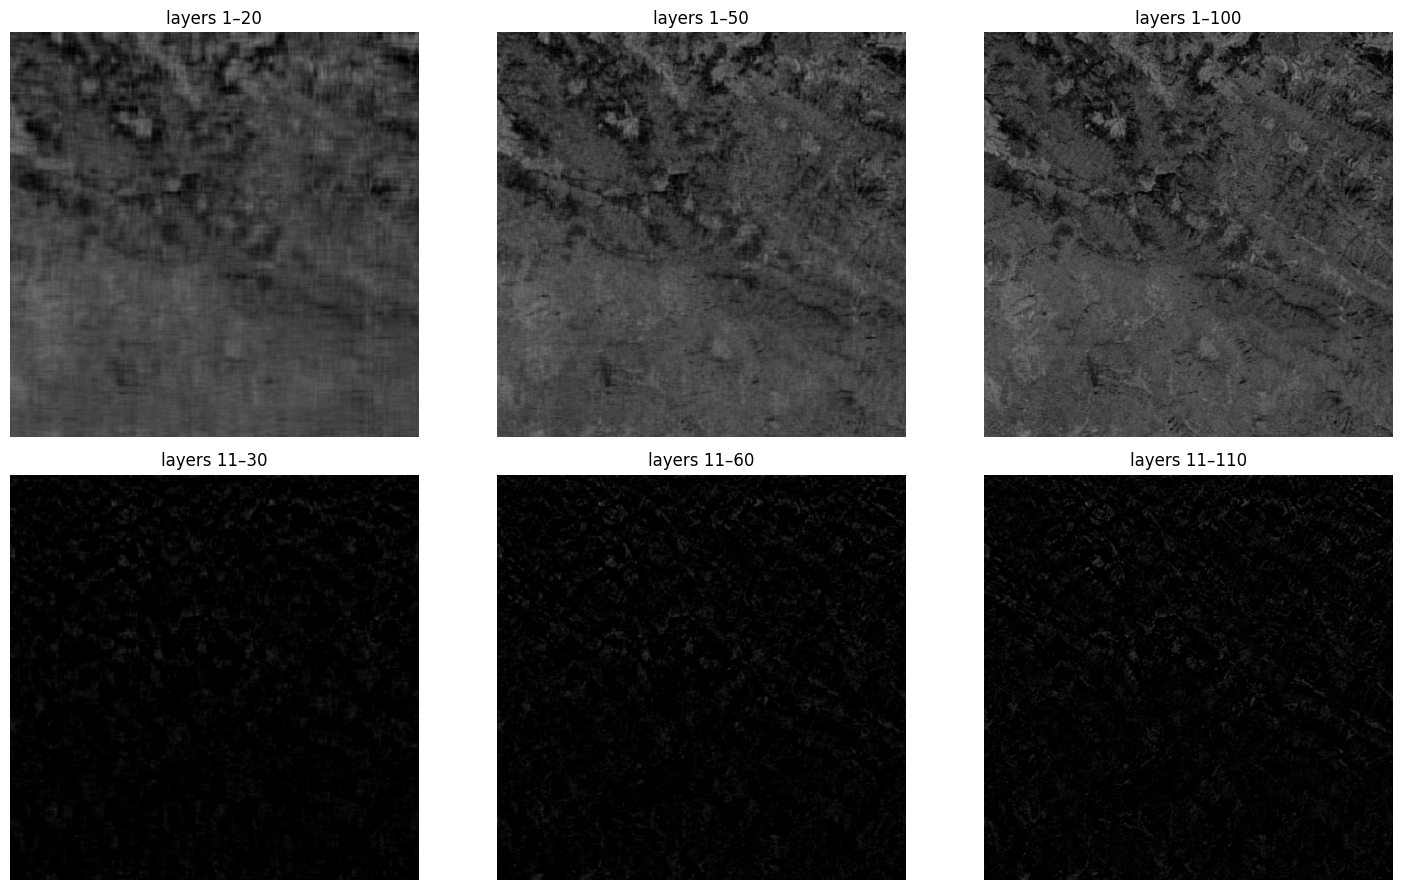

In [14]:
ks = [20, 50, 100]
fig, axes = plt.subplots(2, len(ks), figsize=(15, 9))

for col, k in enumerate(ks):
    first_k   = reconstruct(U, sigma, Vt, 0, k)
    shifted_k = reconstruct(U, sigma, Vt, 10, k + 10)

    axes[0, col].imshow(first_k, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(f"layers 1–{k}")
    axes[1, col].imshow(shifted_k, cmap='gray', vmin=0, vmax=255)
    axes[1, col].set_title(f"layers 11–{k+10}")

for a in axes.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

As seen previously, including the first few layers is more important, than having a lot more of any other layers. The amount of the energy of the first layer is 91%. That amount can not be replaced by any other layer combination. The image created with 100 layers from 11th to 110th is nothing in comparison to the combination of first 20 layers.

In [15]:
terrain_files = {
    "Sea":  "/content/drive/My Drive/water.png", #Baltic Sea near the Aland Islands
    "Forest": "/content/drive/My Drive/forest.png", #Forest of the Bieszczady Mountains
    "Urban":  "/content/drive/My Drive/urban.png", #Katowice, Poland
}
SIZE = (512, 512) #let them have the equal size

Now it's time to compare different land categories

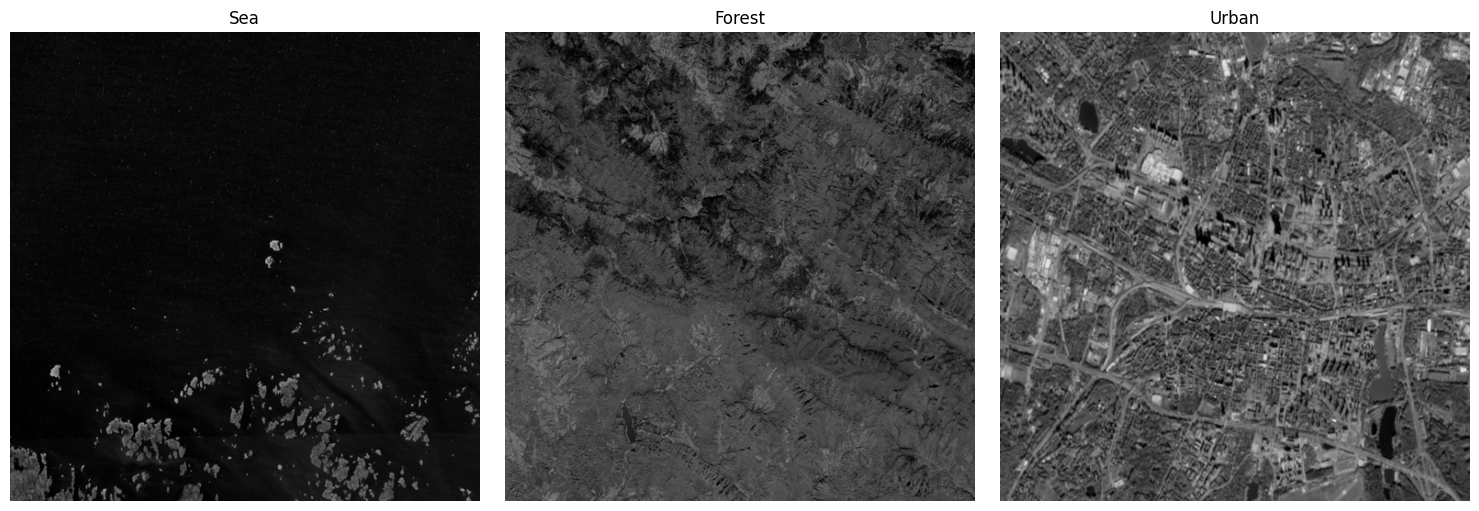

In [16]:
terrains = {}
for name, path in terrain_files.items():
    img = Image.open(path).convert('L').resize(SIZE)
    terrains[name] = np.array(img, dtype=float)

fig, axes = plt.subplots(1, len(terrains), figsize=(15, 5))
for ax, (name, mat) in zip(axes, terrains.items()):
    ax.imshow(mat, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [17]:
results = {}
for name, mat in terrains.items():
    U_t, s_t, Vt_t = np.linalg.svd(mat, full_matrices=False)
    energy_t = np.cumsum(s_t**2) / np.sum(s_t**2) # i am using the energy introduced in the previous cells
    results[name] = {"U": U_t, "sigma": s_t, "Vt": Vt_t, "energy": energy_t}

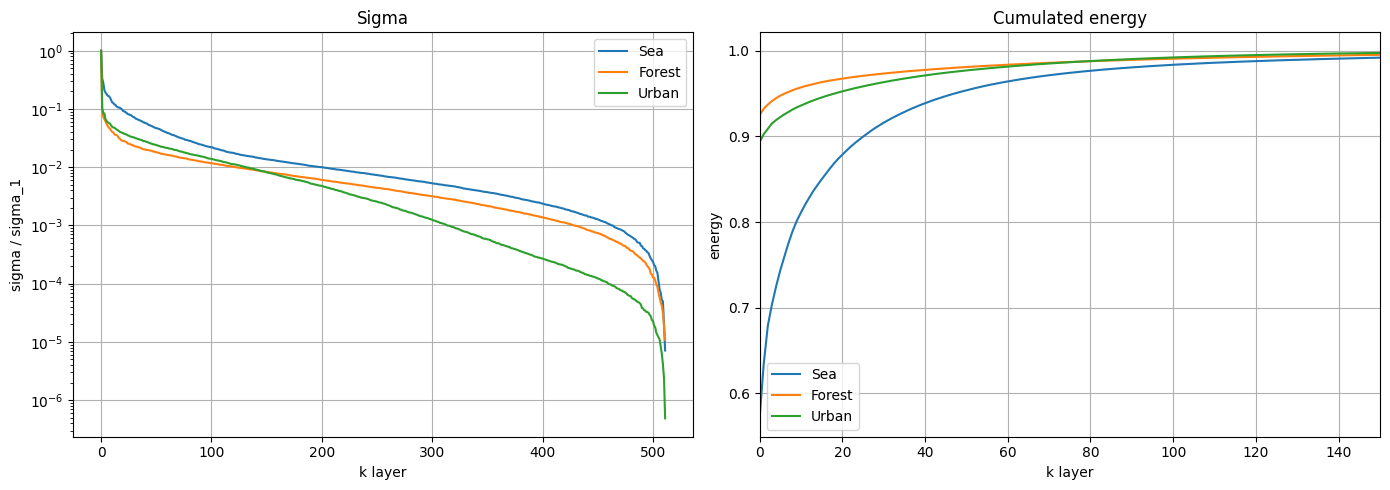

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for name, r in results.items():
    ax[0].semilogy(r["sigma"] / r["sigma"][0], label=name) #comparing sigma by the first (biggest) one
    ax[1].plot(r["energy"], label=name)

ax[0].set_title("Sigma")
ax[0].set_xlabel("k layer")
ax[0].set_ylabel("sigma / sigma_1")

ax[1].set_title("Cumulated energy")
ax[1].set_xlabel("k layer")
ax[1].set_ylabel("energy")
ax[1].set_xlim(0, 150)

for a in ax:
    a.legend()
    a.grid(True)
plt.tight_layout()
plt.show()

Even though all of the lines show a similar trend, we can observe that the normalized sigma curve for the sea stays the highest, while its energy curve grows the slowest. In other words, for the sea image the first layer is much less dominant than for the other terrains, so more layers are needed to reach the same share of energy.
At first this seems surprising, because the sea looks like the simplest image. The explanation lies in what the first layer represents, since it mostly captures the overall brightness of the image. The forest and urban images are evenly grey, so their average brightness alone accounts for most of their energy (around 90% in the first layer). The sea image, on the other hand, is almost completely black, so its average brightness is close to zero and the first layer has little to capture. Most of its energy comes from the bright islands on a dark background and from the fine noise of the water surface, and these are spread over many layers. It is also worth noting that this image is not a uniform ocean, but an archipelago (the Aland Islands) with irregular coastlines.

In [19]:
print(f"{'Terrain':<10}{'90%':>8}{'95%':>8}{'99%':>8}")
for name, r in results.items():
    ks = [np.argmax(r["energy"] >= p) + 1 for p in [0.90, 0.95, 0.99]]
    print(f"{name:<10}{ks[0]:>8}{ks[1]:>8}{ks[2]:>8}")

Terrain        90%     95%     99%
Sea             27      49     136
Forest           1       8      96
Urban            2      20      90


The table shows how many layers k are needed to keep a certain amount of the image energy. The forest and urban images reach 90% of their energy with only 1 and 2 layers respectively, while the sea needs 27. However, this does not mean that 1 or 2 layers are enough to reconstruct the forest or the city. As shown in the previous figures, an image built from a single layer is unrecognizable. The first layer mostly represents the average brightness, which in evenly grey images carries most of the energy, but very little of the actual content.
The differences become smaller at higher thresholds: to reach 99% of the energy, the forest needs 96 layers, the city 90 and the sea 136. This suggests that 99% is a more meaningful threshold than 90% when assessing image quality.

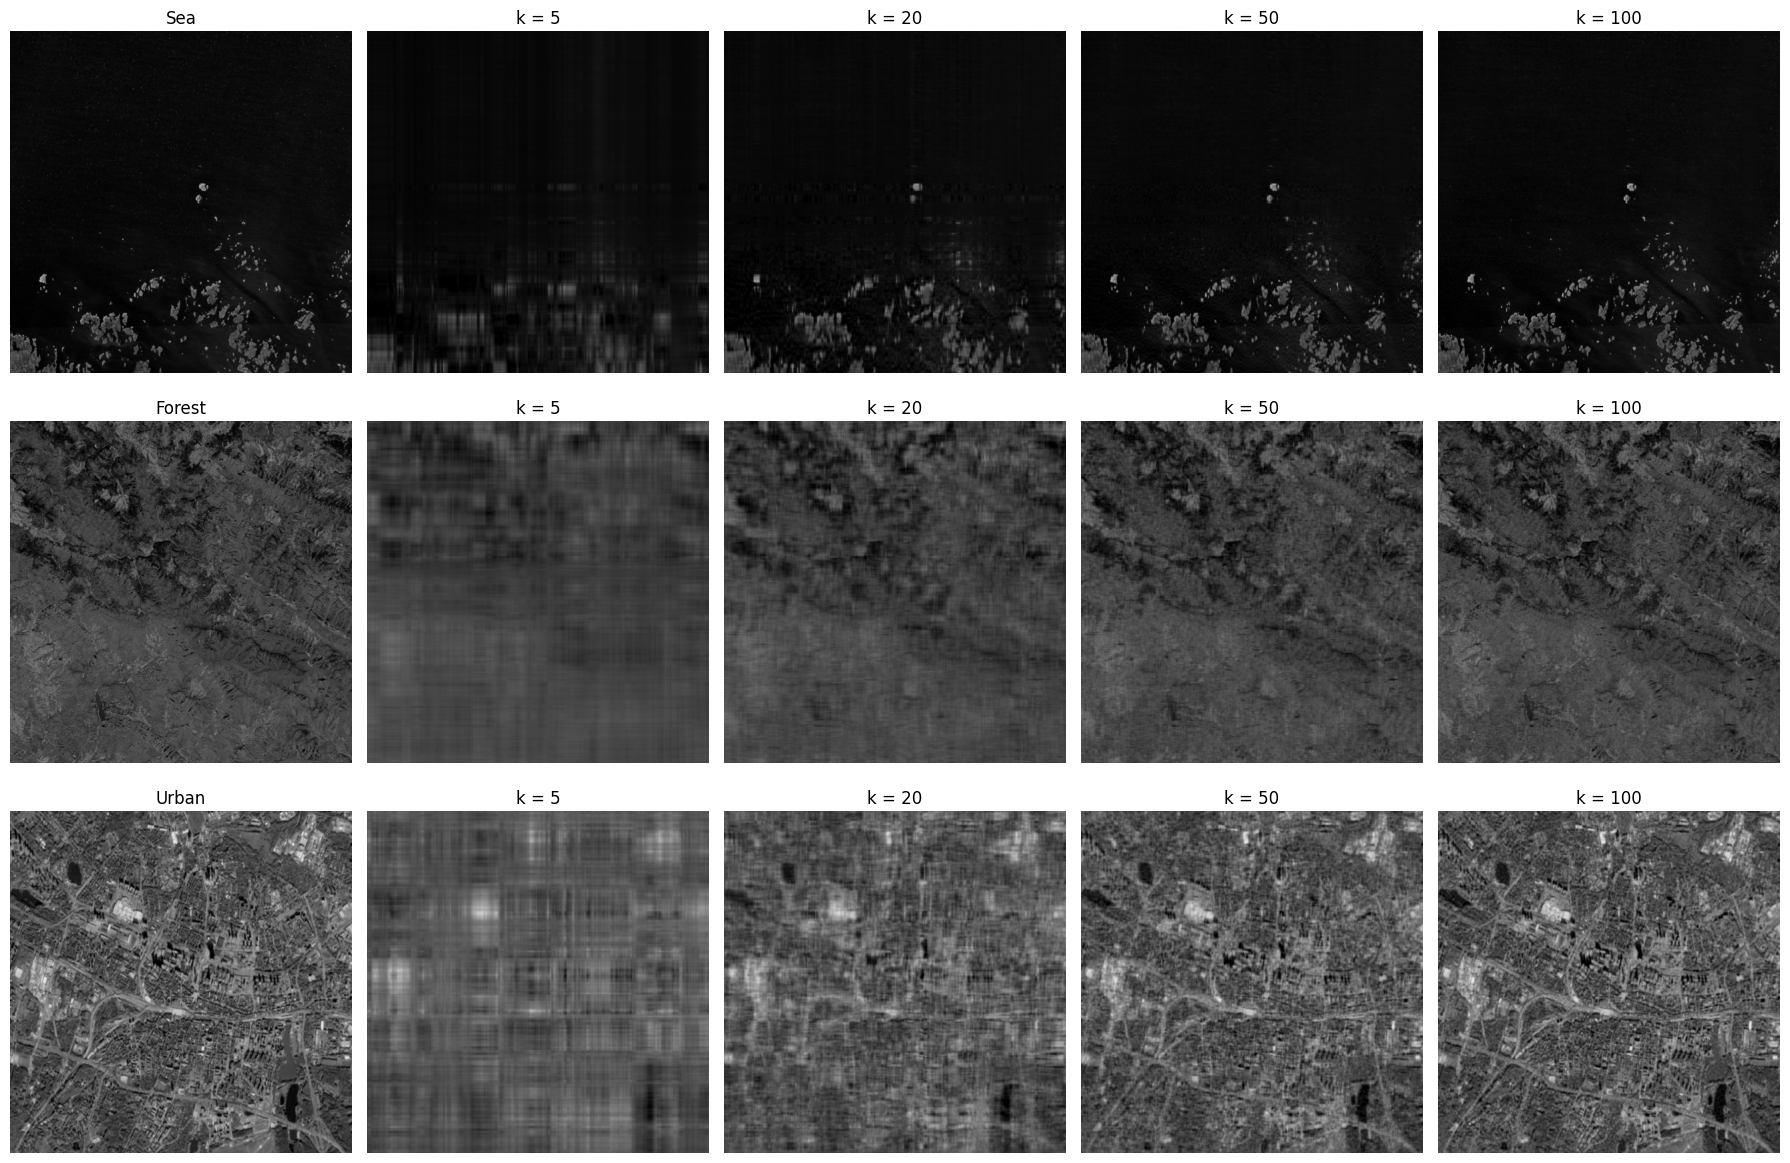

In [20]:
ks = [5, 20, 50, 100]
names = list(results.keys())
fig, axes = plt.subplots(len(names), len(ks) + 1, figsize=(18, 4 * len(names)))

for row, name in enumerate(names):
    r = results[name]
    axes[row, 0].imshow(terrains[name], cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f"{name}")
    for col, k in enumerate(ks, start=1):
        rec = reconstruct(r["U"], r["sigma"], r["Vt"], 0, k)
        axes[row, col].imshow(rec, cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f"k = {k}")

for a in axes.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

Analyzing the figure above, we can observe that for the forest and urban images the land classes can be distinguished at k = 20, but the images are still visibly blurred. At k = 50 the forest looks very close to the original, while the city needs around k = 100 to restore fine details such as individual buildings and small streets.
The sea behaves differently than the energy table suggests. Despite needing the most layers to reach 90% of the energy, it is visually well reconstructed already at k = 20, where the islands and coastlines are clearly visible. This is because most of the sea image is uniformly dark water, which is easy to reconstruct, and the remaining energy lies mostly in fine noise of the water surface, which the eye barely notices.
This shows an important limitation of the energy measure: it does not always agree with visual perception. Energy treats every pixel difference equally, while our eyes focus on shapes and structures. Therefore, the number of layers needed should be judged using both methods together.